# PC2 - De una consulta estructurada a recuperación densa verificable

**Tema (continuación de la PC1):** detección de contradicciones normativas. En la PC1 el par (Norma A, Norma B) llegaba ya emparejado al clasificador. Aquí se construye la pieza anterior: dada una necesidad de información, recuperar los passages que regulan el mismo supuesto, es decir, los candidatos a contradicción.

```text
necesidad (Q0) -> Qwen2.5-0.5B-Instruct -> JSON -> JSON Schema -> Q1
Q0 / Q1 -> "query: " + E5 -> FAISS IndexFlatIP -> top-k -> Recall@k
```

## 0. Instalación, directorio de trabajo y configuración

In [1]:
!python -m pip install -q --break-system-packages torch "transformers>=4.44" sentence-transformers faiss-cpu jsonschema scikit-learn pandas matplotlib

In [2]:
from __future__ import annotations

import os, json, re, random
from typing import Any

import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

if os.path.basename(os.getcwd()) == 'notebook':
    os.chdir('..')
print('cwd:', os.getcwd())
os.makedirs('results', exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DENSE_MODEL_ID = 'intfloat/multilingual-e5-small'
GENERATOR_MODEL_ID = 'Qwen/Qwen2.5-0.5B-Instruct'

RUN_REAL_RETRIEVAL = os.environ.get('CC0F4_RUN_REAL_RETRIEVAL', '1') == '1'
RUN_REAL_LLM = os.environ.get('CC0F4_RUN_REAL_LLM', '1') == '1'

TARGET_WORDS = {'small': 100, 'baseline': 180, 'large': 320}   # variable del Experimento 2
BASELINE = 'baseline'
OVERLAP_PASSAGES = 1                                           # fijo en todas las condiciones
TOP_K_VALUES = [1, 3, 5]
MAX_NEW_TOKENS = 96

print('RUN_REAL_RETRIEVAL:', RUN_REAL_RETRIEVAL, '| RUN_REAL_LLM:', RUN_REAL_LLM)
pd.set_option('display.max_colwidth', 110)

cwd: /workspace/CC-0F4/Evaluaciones/pc2_v2
RUN_REAL_RETRIEVAL: True | RUN_REAL_LLM: True


## 1. Corpus, consultas y qrels

- `data/corpus.jsonl`: 10 documentos normativos **sintéticos**; cada `passage` es un artículo completo con `passage_id` (`D05-A06` = documento D05, artículo 6). Contienen literalmente las 18 normas de los 9 pares de la PC1 más artículos distractores. Procedencia en `data/README_corpus.md`.
- `data/queries.jsonl`: 6 necesidades de información (Q0) redactadas por el autor, una por cada caso 1 a 6 de la PC1.
- `data/qrels.json`: para cada consulta, los `passage_id` de la Norma A y la Norma B de ese caso, siempre en documentos distintos. Como en el Cuaderno 5, la relevancia está definida sobre `passage_id` y no depende del `chunk_id`.

In [3]:
def read_jsonl(path: str) -> list[dict[str, Any]]:
    with open(path, encoding='utf-8') as fh:
        return [json.loads(line) for line in fh if line.strip()]

documents = read_jsonl('data/corpus.jsonl')
queries = read_jsonl('data/queries.jsonl')
qrels = json.load(open('data/qrels.json', encoding='utf-8'))
query_by_id = {q['query_id']: q for q in queries}
passage_text = {p['passage_id']: p['text'] for d in documents for p in d['passages']}
passage_doc = {p['passage_id']: d['doc_id'] for d in documents for p in d['passages']}

# validaciones del benchmark
assert len({d['doc_id'] for d in documents}) == len(documents), 'doc_id duplicado'
assert len(passage_text) == sum(len(d['passages']) for d in documents), 'passage_id duplicado'
assert set(qrels) == set(query_by_id), 'cada consulta necesita qrels'
for qid, gold in qrels.items():
    assert gold and all(pid in passage_text for pid in gold), qid
    assert len({passage_doc[pid] for pid in gold}) == len(gold), 'las evidencias deben estar en documentos distintos'
    for r in query_by_id[qid]['relevantes']:
        assert r['evidencia'] in passage_text[r['passage_id']], (qid, r['passage_id'])

print(pd.DataFrame([{'doc_id': d['doc_id'], 'titulo': d['title'], 'passages': len(d['passages']),
                     'palabras': sum(len(p['text'].split()) for p in d['passages'])} for d in documents]).to_string(index=False))
print()
print(pd.DataFrame([{'query_id': q['query_id'], 'caso_pc1': q['caso_pc1'], 'Q0': q['query'],
                     'qrels': ', '.join(qrels[q['query_id']])} for q in queries]).to_string(index=False))

doc_id                                                    titulo  passages  palabras
   D01           REGLAMENTO DE OBLIGACIONES TRIBUTARIAS FORMALES        10       380
   D02  DIRECTIVA DE FACILIDADES PARA EL CUMPLIMIENTO TRIBUTARIO         8       288
   D03                 ORDENANZA DE GESTIÓN DE LA ZONA RESERVADA         8       273
   D04     REGLAMENTO DE TURISMO Y TRANSPORTE EN ÁREAS NATURALES         7       242
   D05   REGLAMENTO DEL PROCEDIMIENTO ADMINISTRATIVO SANCIONADOR         8       268
   D06                             REGLAMENTO INTERNO DE TRABAJO         8       253
   D07       DIRECTIVA DE LICENCIAS Y AUTORIZACIONES MUNICIPALES         7       217
   D08        LINEAMIENTOS DE TRANSPARENCIA Y GOBIERNO MUNICIPAL         7       230
   D09 DIRECTIVA DE GESTIÓN DE ESTABLECIMIENTOS DEL SECTOR SALUD         6       177
   D10       RÉGIMEN DEL PERSONAL DE LA ADMINISTRACIÓN MUNICIPAL         7       216

query_id  caso_pc1                                              

## 2. Segmentación

`build_chunks`: agrupa passages completos de un mismo documento hasta no superar `target_words`, y el siguiente fragmento empieza `overlap_passages` passages antes del final del anterior. Un passage nunca se parte, así que cada `passage_id` relevante queda entero en al menos un fragmento en cualquier condición.

In [4]:
def word_count(text: str) -> int:
    return len(text.split())


def build_chunks(documents, target_words: int, overlap_passages: int):
    if target_words <= 0:
        raise ValueError('target_words debe ser > 0')
    if overlap_passages < 0:
        raise ValueError('overlap_passages debe ser >= 0')
    chunks = []
    for doc in documents:
        passages = doc['passages']
        start, chunk_number = 0, 1
        while start < len(passages):
            selected, total_words, end = [], 0, start
            while end < len(passages):
                n_words = word_count(passages[end]['text'])
                if selected and total_words + n_words > target_words:
                    break
                selected.append(passages[end]); total_words += n_words; end += 1
            if not selected:   # un passage más largo que target_words se conserva completo
                selected, end = [passages[start]], start + 1
                total_words = word_count(selected[0]['text'])
            chunks.append({'chunk_id': f"{doc['doc_id']}-C{chunk_number:03d}", 'doc_id': doc['doc_id'],
                           'title': doc['title'], 'passage_ids': [p['passage_id'] for p in selected],
                           'n_words': total_words, 'text': ' '.join(p['text'] for p in selected)})
            if end >= len(passages):
                break
            next_start = max(start + 1, end - overlap_passages)
            expected = min(overlap_passages, max(0, len(selected) - 1))
            if end - next_start != expected:
                raise RuntimeError(f'Overlap inconsistente: esperado={expected}, obtenido={end - next_start}')
            start, chunk_number = next_start, chunk_number + 1
    return chunks


chunk_sets = {name: build_chunks(documents, tw, OVERLAP_PASSAGES) for name, tw in TARGET_WORDS.items()}

for name, chunks in chunk_sets.items():
    covered = {pid for c in chunks for pid in c['passage_ids']}
    assert covered == set(passage_text), f'{name}: hay passages sin fragmento'

seg_stats = pd.DataFrame([{'condicion': n, 'target_words': TARGET_WORDS[n], 'overlap_passages': OVERLAP_PASSAGES,
                           'n_fragmentos': len(cs), 'palabras_media': round(np.mean([c['n_words'] for c in cs]), 1),
                           'palabras_min': min(c['n_words'] for c in cs), 'palabras_max': max(c['n_words'] for c in cs),
                           'fragmentos_por_doc': round(len(cs) / len(documents), 1)} for n, cs in chunk_sets.items()])
seg_stats

,condicion,target_words,overlap_passages,n_fragmentos,palabras_media,palabras_min,palabras_max,fragmentos_por_doc
0,small,100,1,49,80.2,50,98,4.9
1,baseline,180,1,20,144.4,91,177,2.0
2,large,320,1,11,234.5,139,288,1.1


## 3. Modelo de embeddings e índice

`intfloat/multilingual-e5-small`: 384 dimensiones, máximo 512 tokens. Se respetan los prefijos `query:` / `passage:` y se normaliza L2. Si un fragmento excede los 512 tokens, la celda **falla**: con truncación el Experimento 2 ya no cambiaría solo la granularidad (Cuaderno 4, sección 1).

`FAISS IndexFlatIP` = búsqueda exhaustiva por producto interno = búsqueda exacta. Con vectores normalizados, producto interno = coseno:

$$\cos(q, p) = \frac{q^\top p}{\lVert q \rVert_2 \lVert p \rVert_2} = \hat q^\top \hat p$$

Se construye un índice por condición de segmentación. El ranking se pide completo (`search_k = ntotal`) y se desempata por `chunk_id`, como en el Cuaderno 5.

In [5]:
class OfflineDenseEncoder:
    def __init__(self, seed: int = 42):
        self.vectorizer = TfidfVectorizer(ngram_range=(1, 2), lowercase=True)
        self.seed, self.svd = seed, None

    def fit_documents(self, texts):
        sparse = self.vectorizer.fit_transform(texts)
        n_components = min(64, sparse.shape[0] - 1, sparse.shape[1] - 1)
        self.svd = TruncatedSVD(n_components=n_components, random_state=self.seed)
        return normalize(self.svd.fit_transform(sparse), norm='l2').astype('float32')

    def encode_queries(self, texts):
        return normalize(self.svd.transform(self.vectorizer.transform(texts)), norm='l2').astype('float32')


if RUN_REAL_RETRIEVAL:
    from sentence_transformers import SentenceTransformer
    import faiss
    dense_encoder = SentenceTransformer(DENSE_MODEL_ID, device='cpu')
    MAX_SEQ = dense_encoder.max_seq_length
    DENSE_IMPLEMENTATION = 'E5 + FAISS IndexFlatIP'
else:
    dense_encoder, MAX_SEQ = None, None
    DENSE_IMPLEMENTATION = 'TF-IDF + SVD + NumPy, solo validación'
print('DENSE_IMPLEMENTATION:', DENSE_IMPLEMENTATION, '| max_seq_length:', MAX_SEQ)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 951.77it/s]


DENSE_IMPLEMENTATION: E5 + FAISS IndexFlatIP | max_seq_length: 512


In [6]:
class DenseRetriever:
    """Recuperador = encoder de consultas + índice + política de ranking (top-k con desempate estable)."""

    def __init__(self, chunks):
        self.chunks = chunks
        texts = [c['text'] for c in chunks]
        if RUN_REAL_RETRIEVAL:
            inputs = ['passage: ' + t for t in texts]
            self.token_lengths = [len(dense_encoder.tokenizer(t, add_special_tokens=True, truncation=False)['input_ids'])
                                  for t in inputs]
            if max(self.token_lengths) > MAX_SEQ:
                raise ValueError(f'Un fragmento excede el límite del encoder: {max(self.token_lengths)} > {MAX_SEQ}')
            self.vectors = dense_encoder.encode(inputs, normalize_embeddings=True, convert_to_numpy=True,
                                                show_progress_bar=False).astype('float32')
            self.index = faiss.IndexFlatIP(self.vectors.shape[1])
            self.index.add(self.vectors)
        else:
            self.token_lengths = None
            self.offline = OfflineDenseEncoder(SEED)
            self.vectors = self.offline.fit_documents(texts)
            self.index = None

    def encode_query(self, text: str) -> np.ndarray:
        if RUN_REAL_RETRIEVAL:
            return dense_encoder.encode(['query: ' + text], normalize_embeddings=True, convert_to_numpy=True,
                                        show_progress_bar=False).astype('float32')
        return self.offline.encode_queries([text])

    def rank(self, text: str, depth: int | None = None):
        qvec = self.encode_query(text)
        if self.index is not None:
            scores, idx = self.index.search(qvec, self.index.ntotal)
            pairs = [(int(i), float(s)) for i, s in zip(idx[0], scores[0]) if int(i) >= 0]
        else:
            scores_all = self.vectors @ qvec[0]
            pairs = [(i, float(s)) for i, s in enumerate(scores_all)]
        pairs.sort(key=lambda p: (-p[1], self.chunks[p[0]]['chunk_id']))
        pairs = pairs[:depth] if depth else pairs
        return [{**self.chunks[i], 'score': s, 'rank': r} for r, (i, s) in enumerate(pairs, start=1)]


retrievers = {name: DenseRetriever(chunks) for name, chunks in chunk_sets.items()}

for name, r in retrievers.items():
    tl = r.token_lengths
    seg_stats.loc[seg_stats.condicion == name, 'tokens_max'] = max(tl) if tl else np.nan
    print(f"{name:9s} vectores: {len(r.vectors):3d}  dim: {r.vectors.shape[1]}  tokens_max: {max(tl) if tl else 'n/a (offline)'}")

small     vectores:  49  dim: 384  tokens_max: 146
baseline  vectores:  20  dim: 384  tokens_max: 248
large     vectores:  11  dim: 384  tokens_max: 412


In [7]:
r = retrievers[BASELINE]
qtext = queries[0]['query']
qvec = r.encode_query(qtext)[0]
numpy_order = np.argsort(-(r.vectors @ qvec), kind='stable')
ranking = r.rank(qtext)
top = ranking[0]
p = r.vectors[[c['chunk_id'] for c in r.chunks].index(top['chunk_id'])]
cos_manual = float(qvec @ p / (np.linalg.norm(qvec) * np.linalg.norm(p)))
print(f"norma(q)={np.linalg.norm(qvec):.4f}  norma(p)={np.linalg.norm(p):.4f}  score índice={top['score']:.4f}  coseno manual={cos_manual:.4f}")
assert np.isclose(top['score'], cos_manual, atol=1e-5)
assert np.allclose(sorted((r.vectors @ qvec).tolist(), reverse=True), [x['score'] for x in ranking], atol=1e-5)
print('Ordenamiento del índice == búsqueda exacta NumPy: OK')

norma(q)=1.0000  norma(p)=1.0000  score índice=0.8957  coseno manual=0.8957
Ordenamiento del índice == búsqueda exacta NumPy: OK


## 4. Recall@k


$$\text{Recall@}k = \frac{|\,\text{passages gold} \cap \text{passages cubiertos por el top-}k\,|}{|\,\text{passages gold}\,|}$$

Un fragmento puede cubrir varios `passage_id`. Las dos evidencias de cada consulta están en documentos distintos y un fragmento nunca cruza documentos, así que **Recall@1 ≤ 0.5 por construcción**. Se registra también el rango del primer fragmento que cubre cada evidencia.

In [8]:
def recall_at_k(ranking, gold, k: int) -> float:
    retrieved = {pid for item in ranking[:k] for pid in item['passage_ids']}
    return len(set(gold) & retrieved) / len(gold)


def first_rank(ranking, pid):
    return next(item['rank'] for item in ranking if pid in item['passage_ids'])


def evaluar(query_id: str, text: str, condicion: str) -> dict:
    ranking = retrievers[condicion].rank(text)
    q = query_by_id[query_id]
    row = {'query_id': query_id, 'condicion': condicion}
    for k in TOP_K_VALUES:
        row[f'R@{k}'] = recall_at_k(ranking, qrels[query_id], k)
    for rel in q['relevantes']:
        row[f"rank_{rel['rol']}"] = first_rank(ranking, rel['passage_id'])
    row['top3'] = [c['chunk_id'] for c in ranking[:3]]
    return row

## 5. Consulta estructurada con el LLM (Semana 3)

Mismo generador que en la PC1, `Qwen/Qwen2.5-0.5B-Instruct`, en CPU, con decoding **greedy** y `max_new_tokens = 96` para que Q1 sea reproducible. El prompt `prompts/estructurar_consulta.txt` separa INSTRUCCIÓN, REGLAS, FORMATO, CONTEXTO y ENTRADA.

Validación en tres niveles:

1. **parseable**: se extrae un objeto JSON del texto generado;
2. **schema-valid**: cumple `data/query_schema.json`;
3. **semánticamente adecuada**: `intent` correcto y `abstain = false`. Si la `query` conserva la necesidad lo mide la recuperación del Experimento 1.

In [9]:
PROMPT_Q1 = open('prompts/estructurar_consulta.txt', encoding='utf-8').read()
SYSTEM = 'Eres un asistente que formula consultas de búsqueda sobre textos normativos peruanos.'

if RUN_REAL_LLM:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    tok = AutoTokenizer.from_pretrained(GENERATOR_MODEL_ID)
    llm = AutoModelForCausalLM.from_pretrained(GENERATOR_MODEL_ID, torch_dtype='auto').to(device)
    llm.eval()
    print('generador:', GENERATOR_MODEL_ID, '| device:', device)

def llm_generate(necesidad: str) -> str:
    if not RUN_REAL_LLM:
        return 'VALIDACION_OFFLINE: no es una salida del LLM canónico.'
    msgs = [{'role': 'system', 'content': SYSTEM},
            {'role': 'user', 'content': PROMPT_Q1.format(necesidad=necesidad)}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors='pt').to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                           temperature=None, top_p=None, top_k=None)
    return tok.decode(out[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)

Loading weights: 100%|██████████| 290/290 [00:03<00:00, 81.73it/s] 


generador: Qwen/Qwen2.5-0.5B-Instruct | device: cpu


In [10]:
from jsonschema import validate, ValidationError

QSCHEMA = json.load(open('data/query_schema.json', encoding='utf-8'))

def extract_json(text: str):
    m = re.search(r'\{.*\}', text, re.S)
    if not m:
        return None
    try:
        obj = json.loads(m.group(0))
        return obj if isinstance(obj, dict) else None
    except json.JSONDecodeError:
        return None

def validar(raw: str, intent_gold: str) -> dict:
    obj = extract_json(raw)
    res = {'json_parseable': obj is not None, 'schema_valid': False, 'error': None, 'obj': obj}
    if obj is not None:
        try:
            validate(obj, QSCHEMA)
            res['schema_valid'] = True
        except ValidationError as e:
            res['error'] = e.message
    res['intent_ok'] = res['schema_valid'] and obj['intent'] == intent_gold
    res['abstain'] = res['schema_valid'] and obj['abstain'] is True
    res['adecuada'] = res['intent_ok'] and not res['abstain']
    return res

for raw in ['{"query": "plazo de apelación", "intent": "plazo", "abstain": false}',
            '{"query": "plazo de apelación", "intent": "deadline", "abstain": false}',
            'La respuesta es quince días.']:
    v = validar(raw, 'plazo')
    print(f"parseable={v['json_parseable']!s:5} schema_valid={v['schema_valid']!s:5} adecuada={v['adecuada']!s:5} | {v['error']}")

parseable=True  schema_valid=True  adecuada=True  | None
parseable=True  schema_valid=False adecuada=False | 'deadline' is not one of ['plazo', 'prohibicion_permiso', 'vigencia', 'obligacion', 'derecho']
parseable=False schema_valid=False adecuada=False | None


In [11]:
q1_rows = []
for q in queries:
    raw = llm_generate(q['query'])
    v = validar(raw, q['intent_gold'])
    q1_rows.append({'query_id': q['query_id'], 'Q0': q['query'], 'raw': raw,
                    'json_parseable': v['json_parseable'], 'schema_valid': v['schema_valid'], 'error': v['error'],
                    'intent_gold': q['intent_gold'], 'intent_pred': v['obj'].get('intent') if v['obj'] else None,
                    'intent_ok': v['intent_ok'], 'abstain': v['abstain'], 'adecuada': v['adecuada'],
                    'Q1': v['obj']['query'] if v['schema_valid'] else None})

with open('results/exp1_consultas.jsonl', 'w', encoding='utf-8') as fh:
    fh.write(json.dumps({'config': {'model': GENERATOR_MODEL_ID if RUN_REAL_LLM else 'OFFLINE',
                                    'prompt': 'prompts/estructurar_consulta.txt', 'decoding': 'greedy',
                                    'max_new_tokens': MAX_NEW_TOKENS}}, ensure_ascii=False) + '\n')
    for row in q1_rows:
        fh.write(json.dumps(row, ensure_ascii=False) + '\n')

pd.DataFrame(q1_rows)[['query_id', 'Q0', 'Q1', 'schema_valid', 'intent_pred', 'intent_ok', 'abstain']]

,query_id,Q0,Q1,schema_valid,intent_pred,intent_ok,abstain
0,N1,"Si soy contribuyente, ¿hasta qué fecha tengo para presentar mi declaración jurada del mes?",None,False,prohibición_permiso,False,False
1,N2,"Quiero entrar con mi auto particular a la zona reservada, ¿está permitido o está prohibido?",None,False,prohibición_permiso,False,False
2,N3,"Me notificaron una resolución y quiero apelarla, ¿cuántos días tengo para presentar la apelación?",apela,True,vigencia,False,False
3,N4,"Mi empresa tiene un permiso de operación, ¿lo tengo que renovar todos los años o dura más tiempo?",None,False,prohibición_permiso,False,False
4,N5,¿Qué entidades están obligadas a publicar su presupuesto anual en internet?,None,False,prohibición_permiso,False,False
5,N6,"Ya cumplí un año trabajando, ¿cuántos días de vacaciones me corresponden?",cuántos días de vacaciones,True,vigencia,False,False


## Experimento 1 - Consulta original (Q0) vs consulta estructurada (Q1)

Variable modificada: el texto que llega al encoder. Fijos: corpus, segmentación `baseline` (`target_words = 180`, `overlap_passages = 1`), E5, normalización L2, `IndexFlatIP`, k.

Si Q1 no es schema-valid o el modelo se abstiene se reportan dos lecturas: **estricta** (no se busca y cuenta como Recall = 0) y **con respaldo** (se busca con Q0).

In [12]:
exp1 = []
for q, r1 in zip(queries, q1_rows):
    qid = q['query_id']
    e0 = evaluar(qid, q['query'], BASELINE)
    ejecutada = bool(r1['schema_valid'] and not r1['abstain'])
    e1 = evaluar(qid, r1['Q1'], BASELINE) if ejecutada else {**{f'R@{k}': 0.0 for k in TOP_K_VALUES}, 'top3': []}
    e1_fb = e1 if ejecutada else e0
    d = e1['R@3'] - e0['R@3']
    exp1.append({'query_id': qid, 'Q1_ejecutada': ejecutada,
                 **{f'Q0_R@{k}': e0[f'R@{k}'] for k in TOP_K_VALUES},
                 **{f'Q1_R@{k}': e1[f'R@{k}'] for k in TOP_K_VALUES},
                 **{f'Q1fb_R@{k}': e1_fb[f'R@{k}'] for k in TOP_K_VALUES},
                 'Q0_rank_A': e0['rank_norma_a'], 'Q0_rank_B': e0['rank_norma_b'],
                 'Q1_rank_A': e1.get('rank_norma_a'), 'Q1_rank_B': e1.get('rank_norma_b'),
                 'top3_comunes': len(set(e0['top3']) & set(e1['top3'])),
                 'efecto_R@3': 'mejora' if d > 0 else ('degrada' if d < 0 else 'conserva'),
                 'Q0_top3': e0['top3'], 'Q1_top3': e1['top3']})

df_exp1 = pd.DataFrame(exp1)
df_exp1.to_csv('results/exp1_recuperacion.csv', index=False)

n = len(q1_rows)
exp1_resumen = {
    'json_parseable_rate': round(sum(r['json_parseable'] for r in q1_rows) / n, 3),
    'schema_valid_rate': round(sum(r['schema_valid'] for r in q1_rows) / n, 3),
    'intent_accuracy': round(sum(r['intent_ok'] for r in q1_rows) / n, 3),
    'abstain_rate': round(sum(r['abstain'] for r in q1_rows) / n, 3),
    **{f'mean_Q0_R@{k}': round(df_exp1[f'Q0_R@{k}'].mean(), 3) for k in TOP_K_VALUES},
    **{f'mean_Q1_R@{k}': round(df_exp1[f'Q1_R@{k}'].mean(), 3) for k in TOP_K_VALUES},
    **{f'mean_Q1fb_R@{k}': round(df_exp1[f'Q1fb_R@{k}'].mean(), 3) for k in TOP_K_VALUES},
    'efecto_R@3': {k: int(v) for k, v in df_exp1['efecto_R@3'].value_counts().items()},
}
print(json.dumps(exp1_resumen, ensure_ascii=False, indent=2))
df_exp1[['query_id', 'Q1_ejecutada', 'Q0_R@1', 'Q0_R@3', 'Q0_R@5', 'Q1_R@1', 'Q1_R@3', 'Q1_R@5',
         'Q0_rank_A', 'Q0_rank_B', 'Q1_rank_A', 'Q1_rank_B', 'top3_comunes', 'efecto_R@3']]

{
  "json_parseable_rate": 1.0,
  "schema_valid_rate": 0.333,
  "intent_accuracy": 0.0,
  "abstain_rate": 0.0,
  "mean_Q0_R@1": 0.5,
  "mean_Q0_R@3": 1.0,
  "mean_Q0_R@5": 1.0,
  "mean_Q1_R@1": 0.167,
  "mean_Q1_R@3": 0.25,
  "mean_Q1_R@5": 0.333,
  "mean_Q1fb_R@1": 0.5,
  "mean_Q1fb_R@3": 0.917,
  "mean_Q1fb_R@5": 1.0,
  "efecto_R@3": {
    "degrada": 5,
    "conserva": 1
  }
}


,query_id,Q1_ejecutada,Q0_R@1,Q0_R@3,Q0_R@5,Q1_R@1,Q1_R@3,Q1_R@5,Q0_rank_A,Q0_rank_B,Q1_rank_A,Q1_rank_B,top3_comunes,efecto_R@3
0,N1,False,0.5,1.0,1.0,0.0,0.0,0.0,1,2,NaN,NaN,0,degrada
1,N2,False,0.5,1.0,1.0,0.0,0.0,0.0,1,3,NaN,NaN,0,degrada
2,N3,True,0.5,1.0,1.0,0.5,0.5,1.0,1,2,4.0,1.0,1,degrada
3,N4,False,0.5,1.0,1.0,0.0,0.0,0.0,2,1,NaN,NaN,0,degrada
4,N5,False,0.5,1.0,1.0,0.0,0.0,0.0,1,3,NaN,NaN,0,degrada
5,N6,True,0.5,1.0,1.0,0.5,1.0,1.0,1,3,1.0,3.0,3,conserva


## Experimento 2 - Tamaño de fragmento

Variable modificada: `target_words` en {100, 180, 320}. Fijos: corpus, consultas **Q0** (para que la variabilidad del LLM no se mezcle con el chunking), qrels, `overlap_passages = 1`, E5, normalización L2, producto interno, `IndexFlatIP`, k.

Métrica principal: **mean Recall@3**.

In [13]:
exp2 = []
for name in TARGET_WORDS:
    for q in queries:
        e = evaluar(q['query_id'], q['query'], name)
        exp2.append({'condicion': name, 'target_words': TARGET_WORDS[name], **{k: v for k, v in e.items() if k != 'condicion'}})

df_exp2 = pd.DataFrame(exp2)
df_exp2.to_csv('results/exp2_por_consulta.csv', index=False)

exp2_mean = (df_exp2.groupby(['condicion', 'target_words'], sort=False)[[f'R@{k}' for k in TOP_K_VALUES]]
             .mean().round(3).reset_index())
exp2_mean['n_fragmentos'] = [len(chunk_sets[c]) for c in exp2_mean['condicion']]
exp2_mean.to_csv('results/exp2_recall.csv', index=False)
print(exp2_mean.to_string(index=False))
print()
print(df_exp2.pivot(index='query_id', columns='condicion', values='R@3')[list(TARGET_WORDS)])

condicion  target_words  R@1  R@3  R@5  n_fragmentos
    small           100  0.5  1.0  1.0            49
 baseline           180  0.5  1.0  1.0            20
    large           320  0.5  1.0  1.0            11

condicion  small  baseline  large
query_id                         
N1           1.0       1.0    1.0
N2           1.0       1.0    1.0
N3           1.0       1.0    1.0
N4           1.0       1.0    1.0
N5           1.0       1.0    1.0
N6           1.0       1.0    1.0


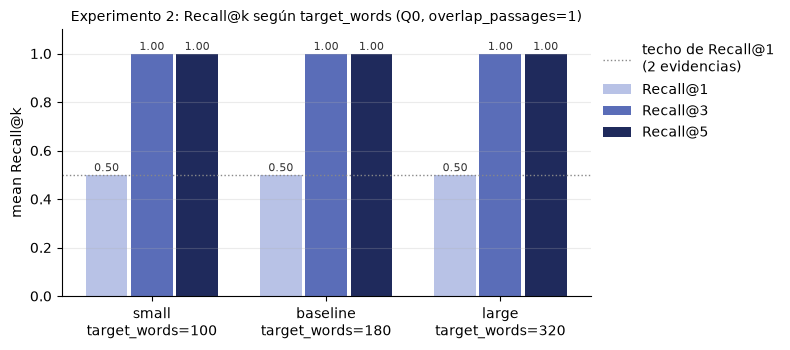

In [14]:
import matplotlib.pyplot as plt

colors = {1: '#B8C2E6', 3: '#5A6DB8', 5: '#1F2A5C'}   # un tono, de claro a oscuro según k
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(exp2_mean)); w = 0.26
for i, k in enumerate(TOP_K_VALUES):
    vals = exp2_mean[f'R@{k}'].values
    bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=colors[k], label=f'Recall@{k}')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f'{v:.2f}', ha='center', fontsize=8, color='#333')
ax.axhline(0.5, ls=':', lw=1, color='#888', label='techo de Recall@1\n(2 evidencias)')
ax.set_xticks(x, [f"{c}\ntarget_words={s}" for c, s in zip(exp2_mean['condicion'], exp2_mean['target_words'])])
ax.set_ylim(0, 1.1); ax.set_ylabel('mean Recall@k')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.set_title('Experimento 2: Recall@k según target_words (Q0, overlap_passages=1)', fontsize=10)
plt.tight_layout(); plt.savefig('results/exp2_recall.png', dpi=200); plt.show()

## 6. Análisis de errores

Para cada consulta con Recall@3 < 1 se muestra qué evidencia faltó, en qué rango apareció y qué fragmentos ocuparon el top-3. Se guarda en `results/errores.md`. Para explicar el error conviene usar los términos del Cuaderno 4: granularidad, contexto incluido, información irrelevante y posición de la evidencia.

In [15]:
def explicar_fallo(query_id: str, text: str, condicion: str, etiqueta: str) -> str:
    q = query_by_id[query_id]
    ranking = retrievers[condicion].rank(text)
    lines = [f'### {query_id} | {etiqueta} | target_words={TARGET_WORDS[condicion]}',
             f'Consulta enviada al encoder: `query: {text}`', '']
    for rel in q['relevantes']:
        rk = first_rank(ranking, rel['passage_id'])
        estado = 'recuperada en top-3' if rk <= 3 else f'NO recuperada en top-3 (rango {rk})'
        lines.append(f"- {rel['rol']} ({rel['passage_id']}): {estado}")
    lines += ['', 'Top-3 recuperado:']
    gold = set(qrels[query_id])
    for c in ranking[:3]:
        hit = sorted(gold & set(c['passage_ids']))
        lines.append(f"{c['rank']}. {c['chunk_id']} score={c['score']:.3f} passages={c['passage_ids']} "
                     f"{'[gold: ' + ', '.join(hit) + ']' if hit else '[sin evidencia gold]'}")
        lines.append(f"   {' '.join(c['text'].split()[:35])} ...")
    return '\n'.join(lines)

bloques = []
q1_by_id = {r['query_id']: r for r in q1_rows}
for q in queries:
    qid = q['query_id']
    casos = [('Q0', q['query'], name) for name in TARGET_WORDS]
    if q1_by_id[qid]['Q1']:
        casos.append(('Q1', q1_by_id[qid]['Q1'], BASELINE))
    for etiqueta, text, name in casos:
        if evaluar(qid, text, name)['R@3'] < 1:
            bloques.append(explicar_fallo(qid, text, name, etiqueta))

errores_md = '# Errores de recuperación (Recall@3 < 1)\n\n' + ('\n\n'.join(bloques) if bloques else 'Ninguna consulta falló en top-3.')
open('results/errores.md', 'w', encoding='utf-8').write(errores_md)
print(errores_md)

# Errores de recuperación (Recall@3 < 1)

### N3 | Q1 | target_words=180
Consulta enviada al encoder: `query: apela`

- norma_a (D05-A06): NO recuperada en top-3 (rango 4)
- norma_b (D06-A07): recuperada en top-3

Top-3 recuperado:
1. D06-C002 score=0.827 passages=['D06-A05', 'D06-A06', 'D06-A07', 'D06-A08'] [gold: D06-A07]
   Artículo 5.- Licencias Se otorga licencia con goce de haber por fallecimiento del cónyuge, padres o hijos por cinco días calendario, y por matrimonio del trabajador por tres días calendario. Artículo 6.- Medidas disciplinarias Las ...
2. D09-C001 score=0.817 passages=['D09-A01', 'D09-A02', 'D09-A03', 'D09-A04', 'D09-A05', 'D09-A06'] [sin evidencia gold]
   Artículo 1.- Ámbito La presente directiva se aplica a los establecimientos de salud públicos y a las entidades que los administran, en lo referido a su organización, gestión y transparencia. Artículo 2.- Responsable técnico Los ...
3. D08-C001 score=0.813 passages=['D08-A01', 'D08-A02', 'D08-A03', 'D08-A04', 'D

## 7. Registro de experimentos

In [16]:
m2 = exp2_mean.set_index('condicion')
resumen = {
    'config': {'run_real_retrieval': RUN_REAL_RETRIEVAL, 'run_real_llm': RUN_REAL_LLM,
               'dense_implementation': DENSE_IMPLEMENTATION, 'generator': GENERATOR_MODEL_ID,
               'decoding_llm': 'greedy', 'max_new_tokens': MAX_NEW_TOKENS, 'normalizacion': 'L2',
               'similitud': 'producto interno (= coseno)', 'target_words': TARGET_WORDS,
               'overlap_passages': OVERLAP_PASSAGES, 'baseline': BASELINE, 'k': TOP_K_VALUES,
               'n_docs': len(documents), 'n_passages': len(passage_text), 'n_queries': len(queries),
               'relevantes_por_query': 2},
    'segmentacion': json.loads(seg_stats.to_json(orient='records')),
    'exp1': exp1_resumen,
    'exp1_por_consulta': json.loads(df_exp1.to_json(orient='records', force_ascii=False)),
    'exp1_consultas': [{k: r[k] for k in ('query_id', 'Q0', 'Q1', 'raw', 'schema_valid', 'intent_pred', 'intent_gold', 'error')}
                       for r in q1_rows],
    'exp2': json.loads(exp2_mean.to_json(orient='records')),
    'exp2_R3_por_consulta': json.loads(df_exp2.pivot(index='query_id', columns='condicion', values='R@3').to_json(orient='index')),
    'n_errores_top3': len(bloques),
}
json.dump(resumen, open('results/resumen.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, allow_nan=False)

e1 = exp1_resumen
registro = f'''| Experimento | Variable modificada | Variable fija | Métrica | Resultado | Conclusión |
|---|---|---|---|---|---|
| Consulta | Q0 original / Q1 estructurada | corpus, target_words=180, overlap_passages=1, E5, IndexFlatIP, k | schema_valid_rate + Recall@k | schema_valid_rate={e1['schema_valid_rate']}; intent_acc={e1['intent_accuracy']}; mean R@3 Q0={e1['mean_Q0_R@3']} vs Q1={e1['mean_Q1_R@3']} (respaldo {e1['mean_Q1fb_R@3']}); efecto R@3: {e1['efecto_R@3']} | (completar) |
| Chunking | target_words 100 / 180 / 320 | corpus, Q0, qrels, overlap_passages=1, E5, L2, IP, IndexFlatIP, k | Recall@1/3/5 | mean R@3: small={m2.loc['small','R@3']}, baseline={m2.loc['baseline','R@3']}, large={m2.loc['large','R@3']} | (completar) |
'''
open('results/registro.md', 'w', encoding='utf-8').write(registro)
print(registro)
if not (RUN_REAL_RETRIEVAL and RUN_REAL_LLM):
    print('ATENCIÓN: corrida en modo offline. Estos números no son evidencia de la práctica.')

| Experimento | Variable modificada | Variable fija | Métrica | Resultado | Conclusión |
|---|---|---|---|---|---|
| Consulta | Q0 original / Q1 estructurada | corpus, target_words=180, overlap_passages=1, E5, IndexFlatIP, k | schema_valid_rate + Recall@k | schema_valid_rate=0.333; intent_acc=0.0; mean R@3 Q0=1.0 vs Q1=0.25 (respaldo 0.917); efecto R@3: {'degrada': 5, 'conserva': 1} | (completar) |
| Chunking | target_words 100 / 180 / 320 | corpus, Q0, qrels, overlap_passages=1, E5, L2, IP, IndexFlatIP, k | Recall@1/3/5 | mean R@3: small=1.0, baseline=1.0, large=1.0 | (completar) |



## 8. Demostración (2 minutos)

Una necesidad -> JSON del LLM -> validación -> consulta enviada al encoder -> top-k -> Recall@k.

In [17]:
def demo(query_id: str, condicion: str = BASELINE, k: int = 5):
    q = query_by_id[query_id]
    print('NECESIDAD (Q0):', q['query'])
    raw = llm_generate(q['query'])
    print('\nSALIDA DEL LLM:', raw)
    v = validar(raw, q['intent_gold'])
    print(f"\nVALIDACIÓN -> parseable={v['json_parseable']} | schema_valid={v['schema_valid']} | "
          f"intent_ok={v['intent_ok']} | abstain={v['abstain']}" + (f" | error: {v['error']}" if v['error'] else ''))
    text = v['obj']['query'] if v['schema_valid'] and not v['abstain'] else q['query']
    print('\nCONSULTA AL ENCODER:', 'query: ' + text)
    ranking = retrievers[condicion].rank(text)
    gold = set(qrels[query_id])
    print(f'\nTOP-{k} ({condicion}, target_words={TARGET_WORDS[condicion]}) | gold: {sorted(gold)}')
    for c in ranking[:k]:
        hit = sorted(gold & set(c['passage_ids']))
        print(f"  {c['rank']}. {c['chunk_id']}  score={c['score']:.3f}  passages={c['passage_ids']}  {'GOLD ' + ','.join(hit) if hit else ''}")
    print('\n' + '  '.join(f'Recall@{kk}={recall_at_k(ranking, qrels[query_id], kk):.2f}' for kk in TOP_K_VALUES))

demo('N3')

NECESIDAD (Q0): Me notificaron una resolución y quiero apelarla, ¿cuántos días tengo para presentar la apelación?

SALIDA DEL LLM: ```json
{
  "query": "apela",
  "intent": "vigencia",
  "abstain": false
}
```

VALIDACIÓN -> parseable=True | schema_valid=True | intent_ok=False | abstain=False

CONSULTA AL ENCODER: query: apela

TOP-5 (baseline, target_words=180) | gold: ['D05-A06', 'D06-A07']
  1. D06-C002  score=0.827  passages=['D06-A05', 'D06-A06', 'D06-A07', 'D06-A08']  GOLD D06-A07
  2. D09-C001  score=0.817  passages=['D09-A01', 'D09-A02', 'D09-A03', 'D09-A04', 'D09-A05', 'D09-A06']  
  3. D08-C001  score=0.813  passages=['D08-A01', 'D08-A02', 'D08-A03', 'D08-A04', 'D08-A05']  
  4. D05-C002  score=0.812  passages=['D05-A05', 'D05-A06', 'D05-A07', 'D05-A08']  GOLD D05-A06
  5. D06-C001  score=0.811  passages=['D06-A01', 'D06-A02', 'D06-A03', 'D06-A04', 'D06-A05']  

Recall@1=0.50  Recall@3=0.50  Recall@5=1.00
